In [1]:
# Modified from https://github.com/aertslab/Nova-ST/blob/main/2.3.StatsCircle.ipynb

# See also figure 3C in https://www.cell.com/cell-reports-methods/fulltext/S2667-2375(24)00204-2?_returnURL=https%3A%2F%2Flinkinghub.elsevier.com%2Fretrieve%2Fpii%2FS2667237524002042%3Fshowall%3Dtrue


In [4]:
# Conda environment: harpy (Frank)

# Stats Circle

This notebook replicates the stats circle plots provided by BGI in their HTML reports using the outputs from STARsolo.

This is not a perfect replication as the analysis pipelines are different, but it is a very close approximation.

Notably, we do not have a count for `non-relevant` HDMIs.

*IMPORTANT TODO:*

Find documentation about *exactly* what the various metrics mean in the NovaScope output.

Some info already:
- https://training.galaxyproject.org/training-material/topics/single-cell/tutorials/scrna-preprocessing-tenx/tutorial.html
- https://github.com/alexdobin/STAR/blob/master/doc/STARmanual.pdf page 22, section 16.1 "Feature statistics summaries"
- https://github.com/alexdobin/STAR/issues/1887

In [1]:
from math import pi
import numpy as np
import matplotlib as mpl
import pandas as pd
import scipy.io as sio

from matplotlib.patches import Patch
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

In [3]:
sample = 'mouse-brain'

In [4]:
group_colours = [
    [(255, 97, 79)],
    [(255, 189, 132), (255, 206, 162)],
    [(162, 210, 135)],
    [(152, 193, 221), (194, 226, 249), (215, 237, 251)],
    [(148, 158, 206), (177, 184, 215)],
    [(247, 188, 255), (237, 210, 240)],
]

group_colours = [[tuple([c / 255 for c in rgb]) for rgb in group] for group in group_colours]

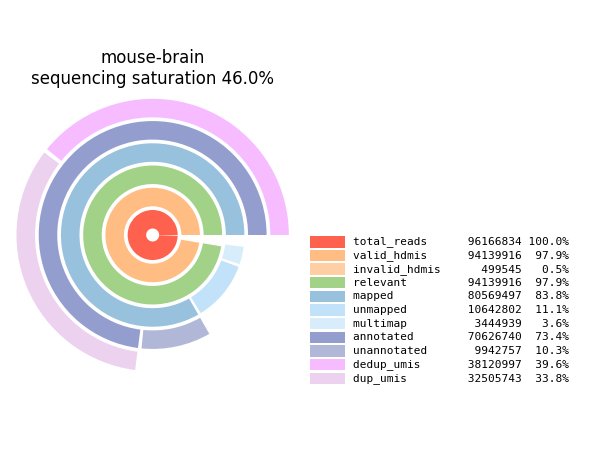

In [5]:
fig = plt.figure() #figsize=(3, 3))
ax = plt.subplot(121, projection="polar")

sample_folder = r"E:\Nova-ST\Exp65-sampleSPC014-novascope_30Jun2025\novascope_output\align\NovaSeq6000_20241107\03D1\Exp65-sampleSPC014\bam"
main_log = {}
with open(f"{sample_folder}/sttoolsLog.final.out") as f:
    for line in f:
        if "|" in line:
            line = line.strip().split("|")
            main_log[line[0].strip()] = line[1].strip()
bc_stats = {}
with open(f"{sample_folder}/sttoolsSolo.out/Barcodes.stats") as f:
    for line in f:
        line = line.strip().split()
        bc_stats[line[0]] = int(line[1])
feature_stats = {}
with open(f"{sample_folder}/sttoolsSolo.out/GeneFull/Features.stats") as f:
    for line in f:
        line = line.strip().split()
        feature_stats[line[0]] = int(line[1])
summary = pd.read_csv(f"{sample_folder}/sttoolsSolo.out/GeneFull/Summary.csv", sep=",", index_col=0, header=None)
mtx = sio.mmread(f"{sample_folder}/sttoolsSolo.out/GeneFull/raw/matrix.mtx.gz")
dedup_umis = mtx.sum()
data = {
    "total_reads": int(summary.loc["Number of Reads"].values[0]),
    "valid_hdmis": bc_stats["yesWLmatchExact"] + bc_stats["yesOneWLmatchWithMM"],
    "invalid_hdmis": bc_stats["noNoWLmatch"] + bc_stats["noUMIhomopolymer"] + bc_stats["noTooManyWLmatches"],
    "discarded_hdmis": 0,
    "not_relevant": 0,
    "mapped": feature_stats["yesWLmatch"] + feature_stats["noNoFeature"],
    "unmapped": feature_stats["noUnmapped"],
    "multimap": feature_stats["MultiFeature"],
    "annotated": feature_stats["yessubWLmatch_UniqueFeature"],
    "unannotated": feature_stats["noNoFeature"],
    "dedup_umis": dedup_umis,
    "dup_umis": feature_stats["yessubWLmatch_UniqueFeature"] - dedup_umis,
}
data["relevant"] = data["valid_hdmis"]
data_norm = {k: v / data["total_reads"] * 100 for k, v in data.items()}
groups = [
    ["total_reads"],
    ["valid_hdmis", "invalid_hdmis"],
    ["relevant"],
    ["mapped", "unmapped", "multimap"],
    ["annotated", "unannotated"],
    ["dedup_umis", "dup_umis"],
]
group_heights = [
    -0.2,
    1,
    2.2,
    3.4,
    4.6,
    5.8,
]

for group, g_colours, height in zip(groups, group_colours, group_heights):
    group_data = [data_norm[k] for k in group]
    group_labels = [k for k in group]
    startangle = 0
    xs = [(i * pi * 2) / 100 for i in group_data]
    for n, (dp, c) in enumerate(zip(xs, g_colours)):
        left = (startangle * pi * 2) / 360  # this is to control where the bar starts
        if n == 0:
            startangle += dp * 360 / (2 * pi)
        else:
            startangle += dp * 360 / (2 * pi)
        dp = dp - ((0.5 * pi * 2) / 100)
        ax.barh(height, dp, left=left, height=1, color=c)

ax.spines.clear()
ax.set_xticks([])
ax.set_yticks([])
sequencing_saturation = float(summary.loc["Sequencing Saturation"].values[0])  # as a fraction in (0, 1)
ax.set_title(f'{sample}\nsequencing saturation {sequencing_saturation* 100:.1f}%')

# Flatten the nested group names and colours lists
names = [x for g in groups for x in g ]
colours = [c for g in group_colours for c in g]
ax2 = plt.subplot(122)
cell_width = 100
cell_height = 12
color_patch_width = 12
color_patch_height = 10
text_gap = 3
nrows = len(names)
ax2.set_xlim(0, cell_width)
ax2.set_ylim(cell_height * nrows * 1.5, -1.5 * cell_height * nrows)
ax2.yaxis.set_visible(False)
ax2.xaxis.set_visible(False)
ax2.set_axis_off()
for i, (name, colour) in enumerate(zip(names, colours)):
    x = 0
    y = (i + 0.5) * cell_height
    ax2.add_patch(Rectangle(xy=(x, y-color_patch_height/2), width=color_patch_width, height=color_patch_height, facecolor=colours[i]))
    label = f'{name:<13} {data[name]:>11} {data_norm[name]:>5.1f}%'
    ax2.text(x + color_patch_width + text_gap, y, label, fontsize=8, fontfamily='monospace', horizontalalignment='left', verticalalignment='center')
plt.tight_layout()
plt.show()

In [6]:
for name in names:
    label = f'{name:<13} {data[name]:>11} {data_norm[name]:>5.1f}%'
    print(label)

total_reads      96166834 100.0%
valid_hdmis      94139916  97.9%
invalid_hdmis      499545   0.5%
relevant         94139916  97.9%
mapped           80569497  83.8%
unmapped         10642802  11.1%
multimap          3444939   3.6%
annotated        70626740  73.4%
unannotated       9942757  10.3%
dedup_umis       38120997  39.6%
dup_umis         32505743  33.8%
